# Assignment 07 — Knowledge Graph (KB), RAG và agent

## 1. Mở đầu: lịch sử, vai trò và ý nghĩa

**Lịch sử.** Ý tưởng biểu diễn tri thức thành thực thể và quan hệ có gốc từ hệ cơ sở tri thức và Semantic Web. Năm 2012, Google giới thiệu Knowledge Graph cho tìm kiếm dựa trên thực thể và quan hệ. Năm 2020, Lewis và cộng sự công bố *Retrieval-Augmented Generation* (RAG): mô hình sinh có thể tham chiếu kho tài liệu truy xuất được thay vì chỉ dựa vào tham số đã học. Xem [Google Research, 2012](https://research.google/blog/new-challenges-in-computer-science-research/) và [Lewis et al., 2020](https://arxiv.org/abs/2005.11401).

**Vai trò.** Knowledge Base (KB) lưu sự kiện có cấu trúc, giúp truy vấn quan hệ và kiểm tra nguồn. RAG tìm các đoạn liên quan rồi đưa chúng vào ngữ cảnh cho mô hình ngôn ngữ, giúp câu trả lời bám vào dữ liệu có thể cập nhật. Agent phối hợp công cụ graph, phép tính chính xác và RAG để xử lý các loại câu hỏi khác nhau. Cả ba không tự biến dữ liệu quan sát thành dự báo hoặc kết luận nhân quả.

**Dataset:** 6.684 phiên AMZN từ 1997-05-15 đến 2023-12-05. Mục tiêu là hỏi đáp và thống kê lịch sử, không dự báo giá hiện tại.

## 2. Knowledge Graph / Knowledge Base

Knowledge Graph gồm **nút** (thực thể hoặc nhóm), **cạnh có nhãn** (quan hệ) và thuộc tính. Một sự kiện có thể viết dưới dạng bộ ba $(s,p,o)$, ví dụ `(year:2023, has_month, month:2023-12)`. Graph trong bài dùng `networkx.DiGraph`; node giữ số liệu, cạnh giữ quan hệ. Truy vấn graph đi theo ID hoặc cạnh, nên câu hỏi đã biết khóa (ngày hay nhóm) được trả lời bằng dữ kiện chính xác.

Các bước xây KB: (1) kiểm tra schema và giá trị thiếu, (2) chọn thực thể/quan hệ, (3) chuẩn hóa ID để không tạo nút trùng, (4) nạp thuộc tính từ CSV, (5) kiểm tra truy vấn so với dữ liệu gốc. **Giới hạn:** graph chỉ biết các sự kiện đã nạp; thiếu cạnh không có nghĩa một quan hệ là sai. Thuộc tính số phải được tính từ CSV, không yêu cầu LLM ước lượng.

Ở Amazon, `AMZN → year → month → session`. Nút phiên lưu Open, High, Low, Close, Adj Close và Volume. Đây là dữ kiện theo ngày; quan hệ thời gian giúp xem cấu trúc theo tháng/năm.

### 2.1. Mô hình hình thức, truy vấn và xuất xứ

Gọi graph là $G=(V,E)$, với $V$ là tập nút và $E\subseteq V\times R\times V$ là các cạnh có nhãn quan hệ thuộc $R$. Bộ ba `(subject, predicate, object)` diễn đạt một liên kết; thuộc tính số và ngày được giữ ở node. `networkx.DiGraph` là lựa chọn gọn cho bài tập. RDF/OWL là hướng biểu diễn theo chuẩn Semantic Web khi cần chia sẻ ontology và suy luận trên nhiều hệ thống, nhưng không cần thiết cho hai CSV này.

**Truy vấn:** trước hết phân tích khóa thực thể trong câu hỏi; sau đó tra node và, nếu cần, duyệt các cạnh liên quan. Truy vấn thống kê cần lọc bản ghi gốc hoặc aggregate đã được kiểm chứng. Mỗi kết quả trả ID nguồn để đối chiếu CSV. Kiểm tra KB bằng đếm nút/cạnh, tính duy nhất của ID, giá trị thiếu và đối chiếu phép nhóm. Graph không tự chứa kiến thức y khoa hay tin tức thị trường ngoài CSV.

## 4. Thiết lập và đọc dữ liệu
Dùng hàm trong `deploy.py` làm cùng một nguồn logic cho notebook và ứng dụng. Cần `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `networkx`, `flask`, `torch`; cài thêm `transformers>=4.51` và `accelerate` khi muốn chạy cell sinh ngôn ngữ.

Ví dụ cài thư viện vào đúng môi trường Python đang chạy notebook:

```bash
python -m pip install pandas matplotlib scikit-learn networkx flask torch "transformers>=4.51,<5" accelerate
```

In [1]:
import importlib.util
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

candidates = [Path("../deploy.py"), Path("deploy.py"), Path("src/Assignment 07/Amazon Stock Price/deploy.py")]
deploy_path = next((p.resolve() for p in candidates if p.exists()), None)
if deploy_path is None:
    raise FileNotFoundError("Không tìm thấy deploy.py của Amazon Stock Price")
spec = importlib.util.spec_from_file_location("amazon_a07", deploy_path)
a07 = importlib.util.module_from_spec(spec)
spec.loader.exec_module(a07)
df = a07.load_data()
print("Nguồn:", a07.DATA_PATH)
print("Kích thước:", df.shape)
display(df.head())

Nguồn: /Users/macos/Docs/Kì 1 năm 4/PTHTTM/src/Assignment 07/Amazon Stock Price/data/AMZN.csv
Kích thước: (6684, 7)


,Date,Open,High,Low,Close,Adj Close,Volume
0,1997-05-15,0.121875,0.125000,0.096354,0.097917,0.097917,1443120000
1,1997-05-16,0.098438,0.098958,0.085417,0.086458,0.086458,294000000
2,1997-05-19,0.088021,0.088542,0.081250,0.085417,0.085417,122136000
3,1997-05-20,0.086458,0.087500,0.081771,0.081771,0.081771,109344000
4,1997-05-21,0.081771,0.082292,0.068750,0.071354,0.071354,377064000


## 5. Mô tả và kiểm tra chất lượng dữ liệu
Kiểm tra kiểu cột, missing, trùng ngày, khoảng thời gian và thống kê mô tả trước khi xây KB. Thứ tự thời gian là quan trọng; phiên giao dịch không diễn ra vào mọi ngày lịch.

In [2]:
audit = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum(), "unique": df.nunique()})
display(audit)
print("Ngày trùng:", df["Date"].duplicated().sum())
print("Khoảng ngày:", df["Date"].min().date(), "→", df["Date"].max().date())
display(df[["Open", "High", "Low", "Close", "Adj Close", "Volume"]].describe().T)

,dtype,missing,unique
Date,datetime64[us],0,6684
Open,float64,0,5952
High,float64,0,5910
Low,float64,0,5915
Close,float64,0,6052
Adj Close,float64,0,6052
Volume,int64,0,6491


Ngày trùng: 0
Khoảng ngày: 1997-05-15 → 2023-12-05


,count,mean,std,min,25%,50%,75%,max
Open,6684.0,3.402932e+01,4.985692e+01,7.031300e-02,2.036875e+00,7.123500e+00,4.520387e+01,1.872000e+02
High,6684.0,3.443920e+01,5.044295e+01,7.239600e-02,2.074750e+00,7.178000e+00,4.547562e+01,1.886540e+02
Low,6684.0,3.358467e+01,4.921355e+01,6.562500e-02,1.994625e+00,6.986750e+00,4.487013e+01,1.848395e+02
Close,6684.0,3.402032e+01,4.982957e+01,6.979200e-02,2.042500e+00,7.104750e+00,4.513575e+01,1.865705e+02
Adj Close,6684.0,3.402032e+01,4.982957e+01,6.979200e-02,2.042500e+00,7.104750e+00,4.513575e+01,1.865705e+02
Volume,6684.0,1.403786e+08,1.390747e+08,9.744000e+06,6.716950e+07,1.039790e+08,1.587810e+08,2.086584e+09


## 6. EDA: xu hướng và phân bố
Biểu đồ cho thấy đường giá Close, histogram Close, phân bố tỷ suất thay đổi theo phiên và Volume. Giá theo thời gian có xu hướng nên histogram gộp toàn kỳ không phải phân bố ổn định.

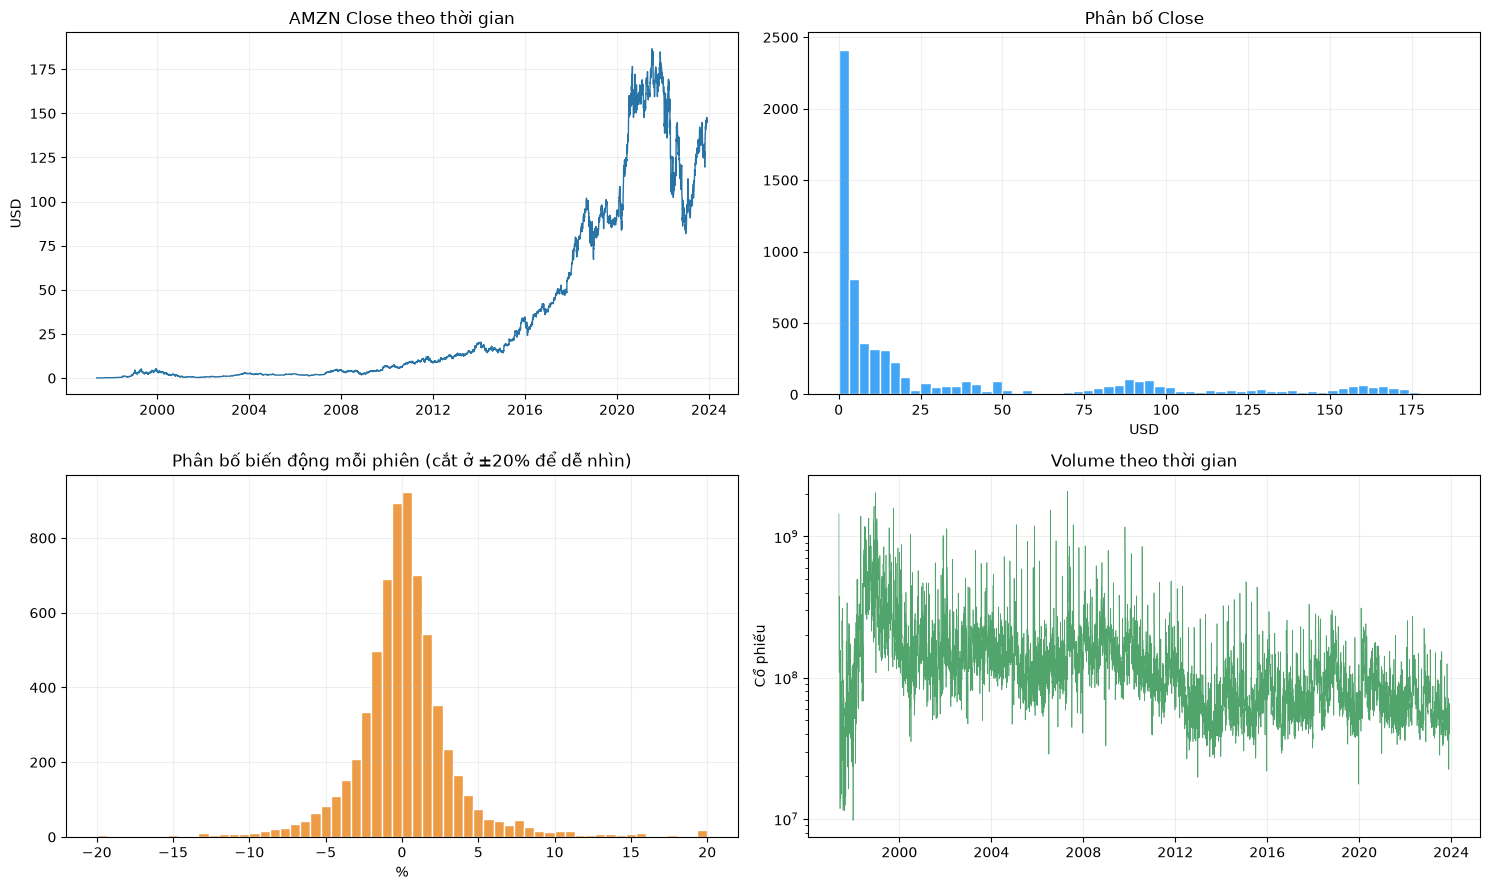

In [3]:
returns = df["Close"].pct_change().dropna() * 100
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0,0].plot(df["Date"], df["Close"], lw=1, color="#2874a6")
axes[0,0].set(title="AMZN Close theo thời gian", ylabel="USD")
axes[0,1].hist(df["Close"], bins=60, color="#42a5f5", edgecolor="white")
axes[0,1].set(title="Phân bố Close", xlabel="USD")
axes[1,0].hist(returns.clip(-20,20), bins=60, color="#ed9b45", edgecolor="white")
axes[1,0].set(title="Phân bố biến động mỗi phiên (cắt ở ±20% để dễ nhìn)", xlabel="%")
axes[1,1].plot(df["Date"], df["Volume"], lw=.5, color="#52a46d")
axes[1,1].set(title="Volume theo thời gian", ylabel="Cổ phiếu", yscale="log")
for ax in axes.flat: ax.grid(alpha=.2)
plt.tight_layout(); plt.show()

## 7. Xây KB và kiểm chứng graph
Mỗi ID phiên có dạng `day:YYYY-MM-DD`. Đếm nút/cạnh và xem các bộ ba mẫu để xác nhận quan hệ được tạo. Truy vấn phiên 2023-12-05 rồi đối chiếu trực tiếp CSV.

In [4]:
graph = a07.build_graph(df)
print("Số nút:", graph.number_of_nodes(), "| Số cạnh:", graph.number_of_edges())
print("Bộ ba mẫu:")
for triple in a07.graph_triples(graph): print(triple)
node = a07.query_graph(graph, "2023-12-05")
print("Graph Close:", node["Close"])
assert node["Close"] == float(df.loc[df["Date"].eq("2023-12-05"), "Close"].iloc[0])

Số nút: 7032 | Số cạnh: 7031
Bộ ba mẫu:
('AMZN', 'has_year', 'year:1997')
('year:1997', 'has_month', 'month:1997-05')
('month:1997-05', 'has_session', 'day:1997-05-15')
('AMZN', 'has_year', 'year:1998')
('AMZN', 'has_year', 'year:1999')
('AMZN', 'has_year', 'year:2000')
Graph Close: 146.880005


## 3. Retrieval-Augmented Generation (RAG)

Pipeline: `CSV → tài liệu có ID nguồn → TF-IDF → truy xuất top-k → ngữ cảnh → Qwen3-0.6B → câu trả lời`. Mỗi tài liệu là một đoạn ngắn có ID ổn định. `TfidfVectorizer(analyzer="char_wb", ngram_range=(3,5))` phù hợp khi câu hỏi có tiếng Việt lẫn tên cột tiếng Anh, không cần tải embedding model. Điểm cosine dùng để xếp hạng; nếu không đủ bằng chứng thì agent từ chối trả lời.

Truy xuất tốt **không bảo đảm** mô hình sinh luôn đúng. Vì thế, số liệu được lấy từ graph/CSV, còn mô hình chỉ diễn đạt từ tài liệu truy xuất và giao diện luôn hiển thị ID nguồn. Qwen3 chạy cục bộ bằng Transformers, tải model vào cache ở lần dùng đầu. Theo [model card Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B), cần Transformers hỗ trợ Qwen3 (từ 4.51); sau khi đã tải, không cần API.

Ở Amazon, corpus gồm một tài liệu cho mỗi phiên và một tài liệu thống kê cho mỗi tháng. ID `AMZN:YYYY-MM-DD` và `AMZN:month:YYYY-MM` cho phép lần lại dữ liệu gốc. Tìm theo ngày dùng graph; câu hỏi mô tả có thể dùng RAG.

### 3.1. Từ tài liệu đến điểm truy xuất

Mỗi tài liệu được tạo có quy tắc từ CSV: ID nguồn, nội dung ngắn và các giá trị có đơn vị. TF-IDF tăng trọng số từ/cụm ký tự đặc trưng của một tài liệu và giảm trọng số phần xuất hiện khắp corpus. Với vector truy vấn $q$ và tài liệu $d$, điểm cosine là $\operatorname{sim}(q,d)=\frac{q\cdot d}{\lVert q\rVert\lVert d\rVert}$. Notebook dùng n-gram ký tự 3–5 và lấy tối đa 4 tài liệu có điểm từ 0,10. Điểm này là mức liên quan văn bản, không phải độ tin cậy thống kê.

**Sinh câu trả lời:** prompt chứa câu hỏi và các tài liệu truy xuất, yêu cầu mô hình chỉ dùng bằng chứng đó. Mô hình có thể diễn đạt sai dù truy xuất đúng, nên agent tách phép tính khỏi sinh văn bản và luôn trả danh sách nguồn. Câu hỏi không có dữ kiện tương ứng phải được báo thiếu dữ liệu. Không đưa toàn bộ 100.000 dòng diabetes hoặc toàn bộ phiên Amazon vào prompt: văn bản quá dài, khó kiểm tra và không cần cho truy vấn tổng hợp.

### 3.2. Agent và đánh giá

Agent là bộ điều phối: nhận câu hỏi → chọn công cụ phù hợp → lấy bằng chứng → trả câu trả lời cùng `sources` và `tools`. Bộ chọn có quy tắc rõ ràng: ngày/nhóm cụ thể đi qua graph; phép gộp số qua CSV; câu hỏi mô tả qua RAG. Với mô hình nhỏ, cách này giữ phép tính chính xác và giúp tái lập kết quả.

Đánh giá riêng từng tầng: (1) **KB** đối chiếu node/aggregate với CSV; (2) **retrieval** kiểm tra nguồn mong đợi có trong top-k; (3) **generation** kiểm tra câu trả lời có được bằng chứng hỗ trợ; (4) **agent** kiểm tra định tuyến, câu hỏi ngoài phạm vi và lỗi đầu vào. Một câu trả lời trôi chảy mà không có nguồn phù hợp vẫn là lỗi.

## 8. Lập chỉ mục và thử truy xuất
Xem điểm tương đồng và nguồn top-k. Truy xuất trả về bằng chứng, chưa phải câu trả lời của LLM.

In [5]:
documents = a07.build_documents(df)
vectorizer, matrix = a07.build_index(documents)
print("Tài liệu:", len(documents), "| Ma trận TF-IDF:", matrix.shape)
for item in a07.retrieve("Amazon tháng 2023-12 Close và Volume", documents, vectorizer, matrix):
    print(item["id"], "score=", item["score"], "|", item["text"][:110])

Tài liệu: 7005 | Ma trận TF-IDF: (7005, 58345)
AMZN:month:2023-12 score= 0.2643 | Amazon AMZN tháng 2023-12: 3 phiên; giá Close trung bình 146.2500 USD, thấp nhất 144.8400 USD, cao nhất 147.03
AMZN:month:2023-11 score= 0.2117 | Amazon AMZN tháng 2023-11: 21 phiên; giá Close trung bình 143.4576 USD, thấp nhất 137.0000 USD, cao nhất 147.7
AMZN:month:2023-10 score= 0.2104 | Amazon AMZN tháng 2023-10: 22 phiên; giá Close trung bình 128.2786 USD, thấp nhất 119.5700 USD, cao nhất 133.0
AMZN:month:2023-02 score= 0.1867 | Amazon AMZN tháng 2023-02: 19 phiên; giá Close trung bình 99.2142 USD, thấp nhất 93.5000 USD, cao nhất 112.910


## 9. Agent: chọn công cụ và câu trả lời có nguồn
Câu hỏi chứa ngày chính xác đi qua graph; khoảng ngày được tính trực tiếp từ CSV; câu hỏi mô tả đi qua RAG. `generate=False` hiển thị chứng cứ truy xuất để notebook có thể chạy trước khi tải model.

In [6]:
agent = a07.AmazonAgent(df)
for question in ["Giá Close ngày 2023-12-05 là bao nhiêu?", "Giá Close từ 2023-12-01 đến 2023-12-05?", "Giá mới nhất trong dữ liệu là gì?"]:
    print("\nHỏi:", question)
    print(agent.ask(question, generate=False))
print("\nRAG không sinh:", agent.ask("Tóm tắt dữ liệu Amazon AMZN", generate=False))


Hỏi: Giá Close ngày 2023-12-05 là bao nhiêu?
{'answer': 'Ngày 2023-12-05, Close của AMZN là 146.8800 USD.', 'sources': ['AMZN:2023-12-05'], 'tools': ['knowledge_graph']}

Hỏi: Giá Close từ 2023-12-01 đến 2023-12-05?
{'answer': 'Từ 2023-12-01 đến 2023-12-05 có 3 phiên. Close: trung bình 146.2500 USD; thấp nhất 144.8400 USD; cao nhất 147.0300 USD.', 'sources': ['AMZN.csv#Date=2023-12-01..2023-12-05'], 'tools': ['csv_statistics']}

Hỏi: Giá mới nhất trong dữ liệu là gì?
{'answer': 'Phiên cuối trong CSV là 2023-12-05; Close 146.8800 USD. Đây không phải giá hiện tại.', 'sources': ['AMZN:2023-12-05'], 'tools': ['knowledge_graph']}

RAG không sinh: {'answer': 'Tóm tắt dữ liệu Amazon AMZN: 6684 phiên giao dịch từ 1997-05-15 đến 2023-12-05. Dataset gồm Date, Open, High, Low, Close, Adj Close và Volume. Đây là giá lịch sử trong CSV, không phải giá hiện tại hoặc dự báo.', 'sources': ['AMZN:overview'], 'tools': ['rag_retrieval']}


## 10. Chạy mô hình ngôn ngữ cục bộ
Đặt `RUN_LOCAL_LLM=True` sau khi cài `transformers>=4.51 accelerate` và cho phép tải Qwen3-0.6B lần đầu. Model chỉ dùng tài liệu được truy xuất. Lần tải đầu cần Internet; những lần sau dùng cache. Cell này chạy Qwen3 khi thực thi notebook; lần tải đầu cần Internet và các thư viện đã nêu.

In [7]:
RUN_LOCAL_LLM = True
if RUN_LOCAL_LLM:
    print(agent.ask("Tóm tắt dữ liệu Amazon AMZN", generate=True))
else:
    print("Đặt RUN_LOCAL_LLM=True để kiểm tra lượt sinh bằng Qwen3 cục bộ.")

/opt/miniconda3/envs/ISD/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'answer': 'Tóm tắt dữ liệu Amazon AMZN: 6684 phiên giao dịch từ 1997-05-15 đến 2023-12-05.', 'sources': ['AMZN:overview'], 'tools': ['rag_retrieval', 'local_llm']}


## 11. Deploy và kết luận
Chạy CLI: `python deploy.py --question "Giá Close ngày 2023-12-05 là bao nhiêu?"`. Chạy web: `python deploy.py --web --port 8007`, rồi mở `http://127.0.0.1:8007`. API nhận `POST /api/chat` với JSON `{"question":"..."}`, trả `answer`, `sources`, `tools`. Kết quả phản ánh lịch sử CSV đến 05/12/2023; câu hỏi giá hiện tại hoặc dự báo nằm ngoài dữ liệu.